Loading dataset

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load historical dataset
DATA_PATH = Path("../data/historical/combined_historical.csv")

historical_df = pd.read_csv(DATA_PATH)

# Convert time column to datetime
historical_df["time"] = pd.to_datetime(
    historical_df["time"],
    utc=True
).dt.tz_convert("Asia/Karachi")

# Display first records
historical_df.head()

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,precipitation_probability,uv_index,us_aqi,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,2024-11-14 00:00:00+05:00,18.4,91,0.0,0.9,101,0.0,0.0,300,353.9,380.9,1794.0,110.3,33.5,18.0
1,2024-11-14 01:00:00+05:00,17.9,93,0.0,1.2,51,0.0,0.0,308,358.6,386.5,1203.0,111.4,33.5,13.0
2,2024-11-14 02:00:00+05:00,17.3,96,0.0,3.1,69,0.0,0.0,316,362.3,390.2,805.0,108.3,32.9,11.0
3,2024-11-14 03:00:00+05:00,17.2,96,0.0,5.4,64,0.0,0.0,324,365.1,392.1,758.0,96.7,30.8,12.0
4,2024-11-14 04:00:00+05:00,17.1,95,0.0,7.3,62,0.0,0.0,332,356.7,380.9,904.0,80.9,28.0,15.0


Inspecting dataset

In [17]:
print("Dataset shape:", historical_df.shape)

print("\nColumn names:")
print(historical_df.columns.tolist())

print("\nData types:")
print(historical_df.dtypes)

print("\nDataset information:")
historical_df.info()

print("\nStatistical summary:")
display(historical_df.describe())

Dataset shape: (17520, 15)

Column names:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'wind_direction_10m', 'precipitation_probability', 'uv_index', 'us_aqi', 'pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone']

Data types:
time                         datetime64[us, Asia/Karachi]
temperature_2m                                    float64
relative_humidity_2m                                int64
precipitation                                     float64
wind_speed_10m                                    float64
wind_direction_10m                                  int64
precipitation_probability                         float64
uv_index                                          float64
us_aqi                                              int64
pm2_5                                             float64
pm10                                              float64
carbon_monoxide                                   float64
nitrog

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,precipitation_probability,uv_index,us_aqi,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
count,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17452.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000,17520.000000
mean,24.470257,62.913756,0.086787,6.245188,181.149772,9.883796,1.691664,156.458276,71.658271,98.405925,1052.491553,40.643390,17.003773,91.195548
std,8.306550,22.686706,0.633169,3.471135,106.693936,21.289403,2.431988,49.442107,51.099267,75.854987,825.229783,33.462346,9.847996,65.049086
min,3.500000,6.000000,0.000000,0.000000,1.000000,0.000000,0.000000,56.000000,3.400000,3.600000,138.000000,0.000000,0.100000,0.000000
25%,18.100000,46.000000,0.000000,3.800000,91.000000,0.000000,0.000000,122.000000,37.300000,51.500000,491.000000,13.800000,10.400000,37.000000
50%,25.900000,66.000000,0.000000,5.800000,152.000000,0.000000,0.050000,155.000000,56.100000,78.200000,752.000000,30.900000,14.200000,75.000000
75%,30.600000,82.000000,0.000000,8.300000,288.000000,7.000000,3.050000,180.000000,88.900000,122.900000,1357.000000,61.500000,20.700000,144.000000
max,46.200000,100.000000,18.000000,29.300000,360.000000,100.000000,8.550000,538.000000,365.100000,890.300000,7504.000000,201.900000,94.400000,293.000000


Checking for missing values and timestamp continuity

In [19]:
# Checking  missing values
print("Missing values:")
print(historical_df.isnull().sum())

# Checking duplicate timestamps
print("\nDuplicate timestamps:")
print(historical_df["time"].duplicated().sum())

# Checking timestamp frequency
time_differences = historical_df["time"].diff().dropna()

print("\nTimestamp intervals:")
print(time_differences.value_counts())

# Checking constant columns
print("\nConstant columns:")
print(
    historical_df.columns[
        historical_df.nunique() <= 1
    ].tolist()
)

Missing values:
time                          0
temperature_2m                0
relative_humidity_2m          0
precipitation                 0
wind_speed_10m                0
wind_direction_10m            0
precipitation_probability    68
uv_index                      0
us_aqi                        0
pm2_5                         0
pm10                          0
carbon_monoxide               0
nitrogen_dioxide              0
sulphur_dioxide               0
ozone                         0
dtype: int64

Duplicate timestamps:
0

Timestamp intervals:
time
0 days 01:00:00    17519
Name: count, dtype: int64

Constant columns:
[]


Visualizing the distributions

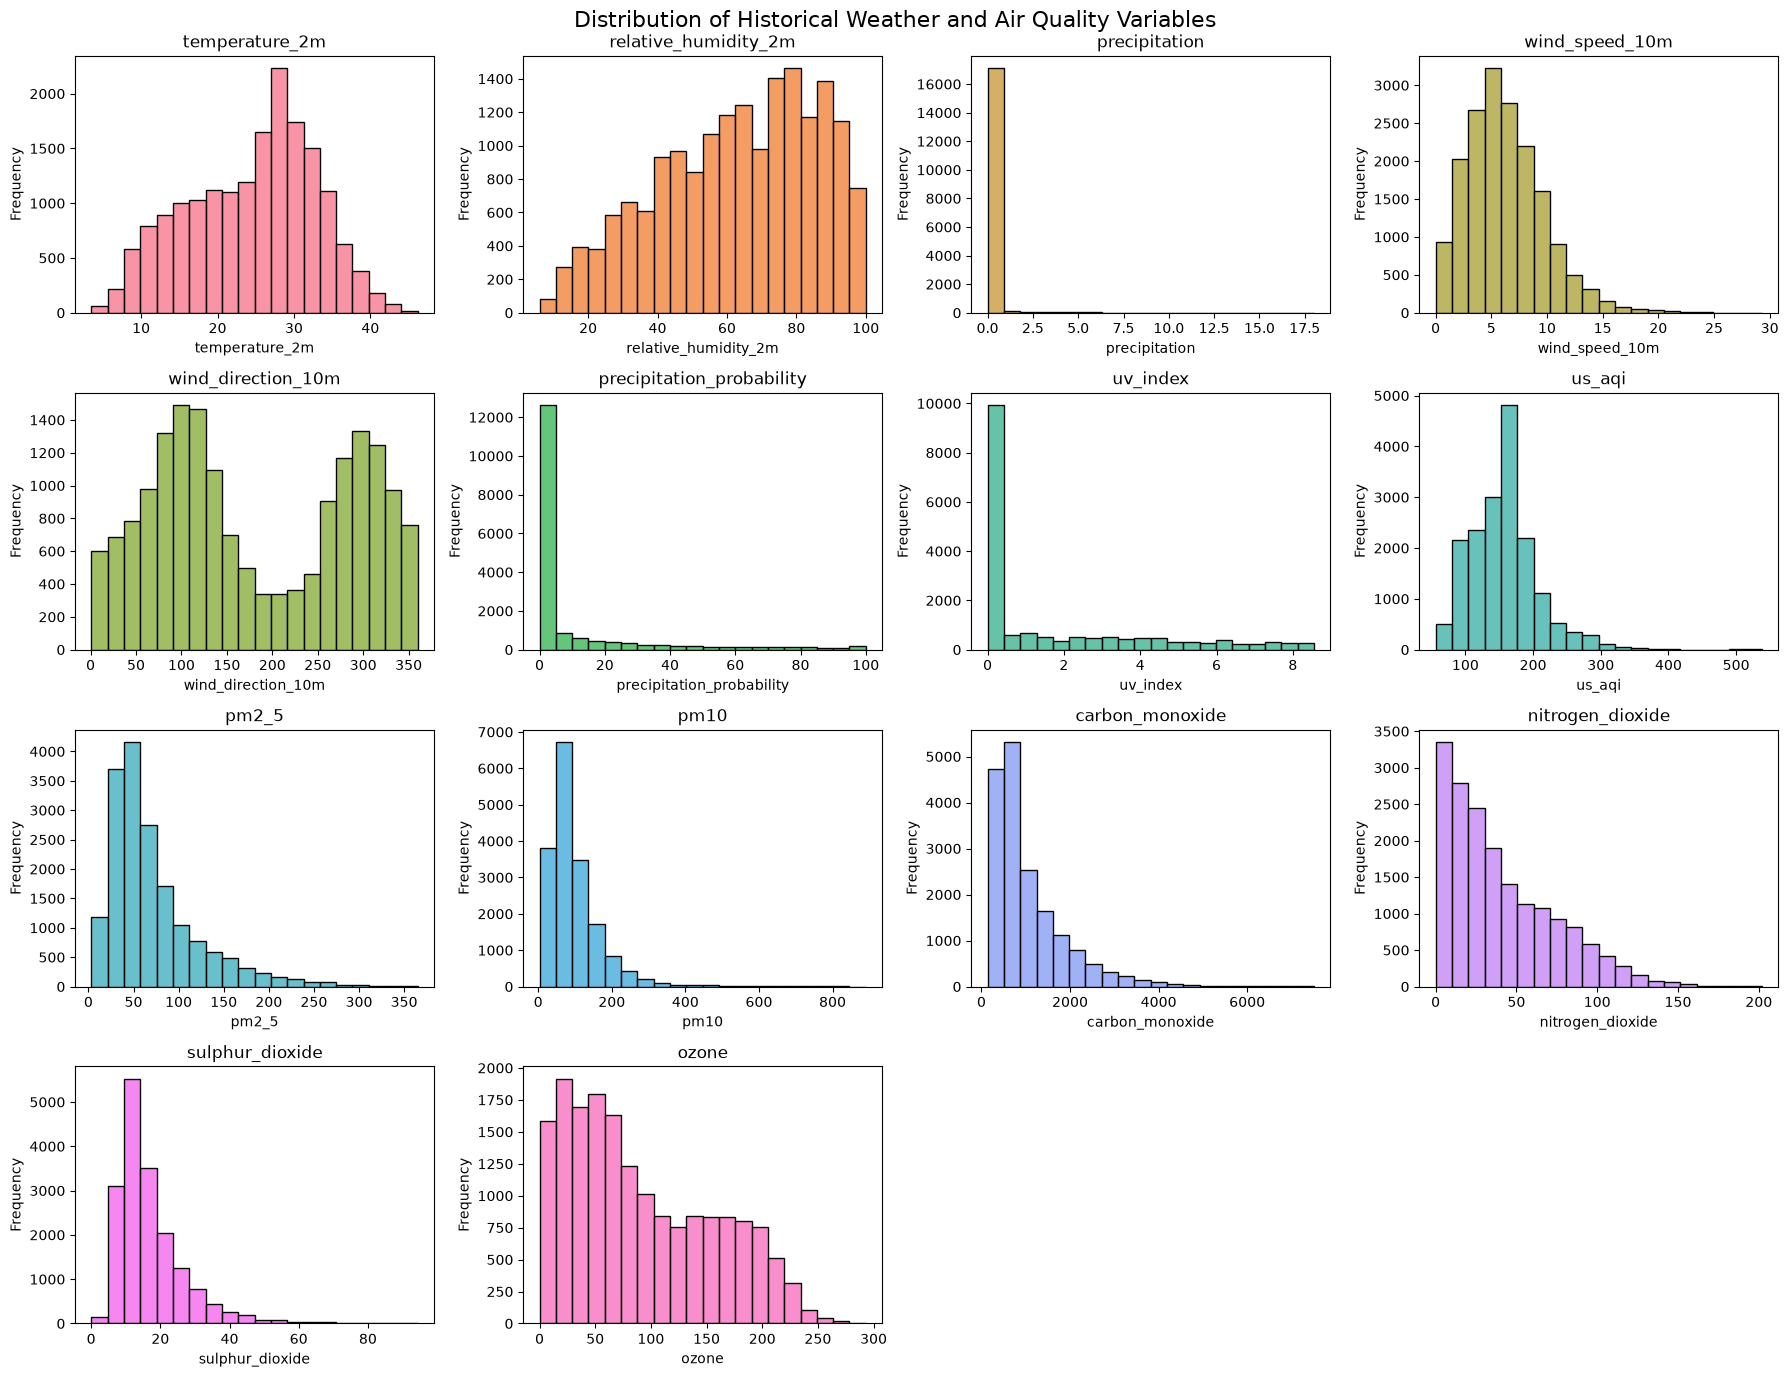

In [20]:
numeric_columns = historical_df.select_dtypes(include=np.number).columns

colors = sns.color_palette("husl", len(numeric_columns))

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(18, 14)
)

axes = axes.flatten()

for i, column in enumerate(numeric_columns):
    sns.histplot(
        data=historical_df,
        x=column,
        bins=20,
        color=colors[i],
        edgecolor="black",
        ax=axes[i]
    )

    axes[i].set_title(column)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")


for i in range(len(numeric_columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle(
    "Distribution of Historical Weather and Air Quality Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

Time-series analysis

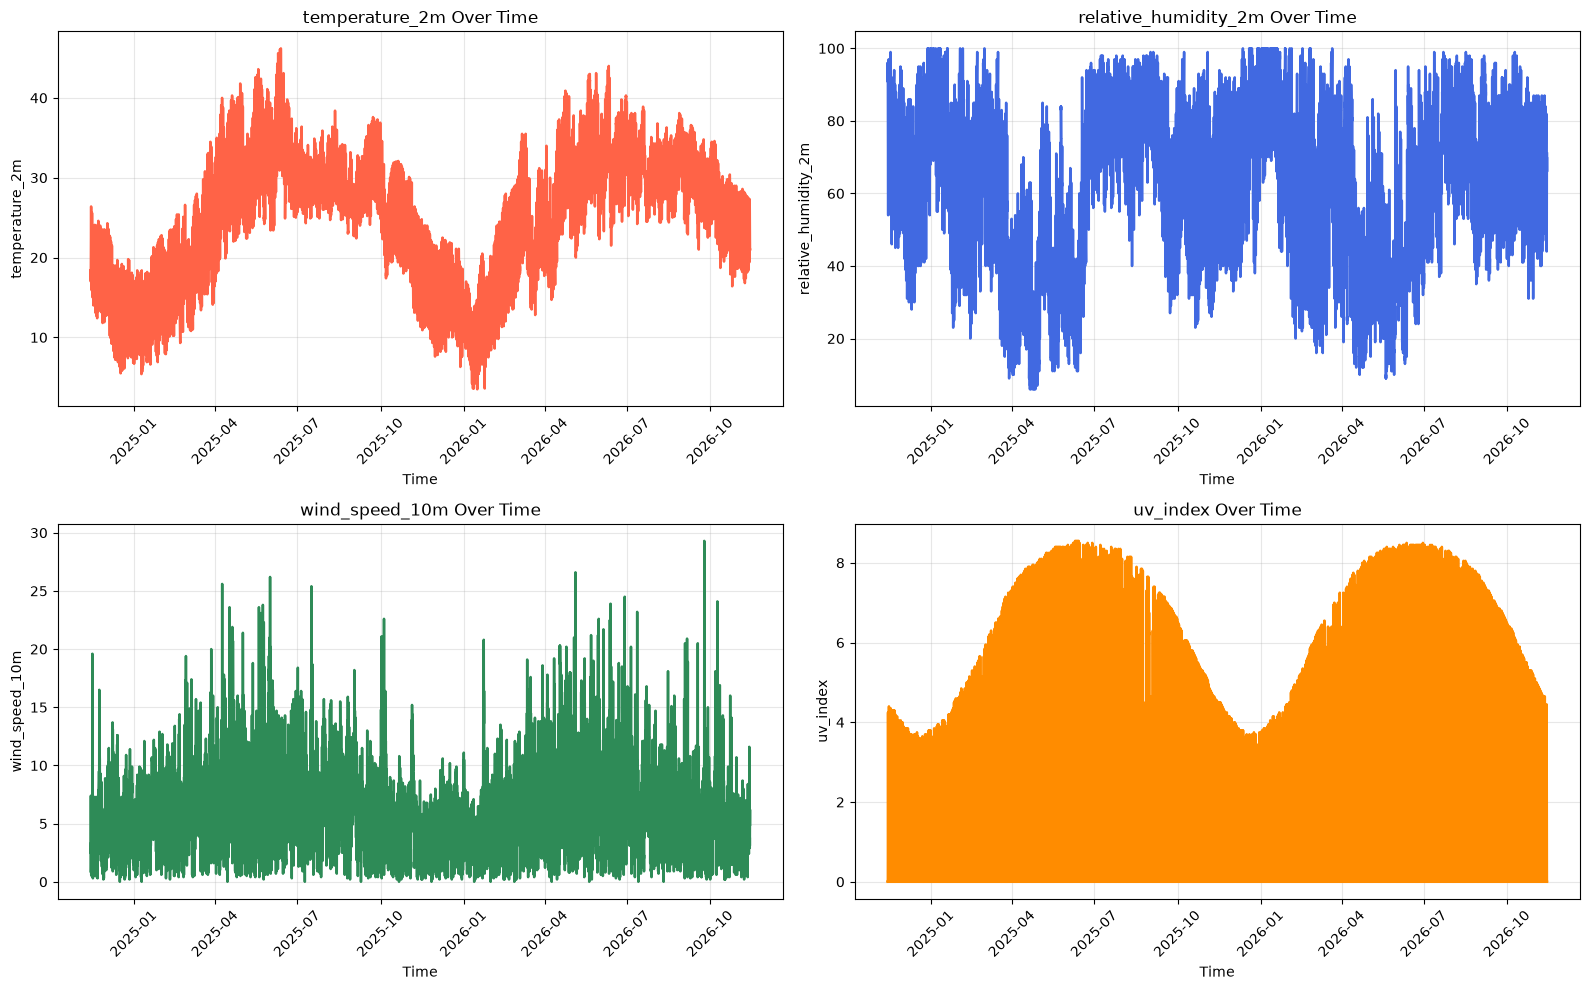

In [21]:
weather_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "uv_index"
]

colors = ["tomato", "royalblue", "seagreen", "darkorange"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 10)
)

axes = axes.flatten()

for i, column in enumerate(weather_columns):
    axes[i].plot(
        historical_df["time"],
        historical_df[column],
        color=colors[i],
        linewidth=1.8
    )

    axes[i].set_title(f"{column} Over Time")
    axes[i].set_xlabel("Time")
    axes[i].set_ylabel(column)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

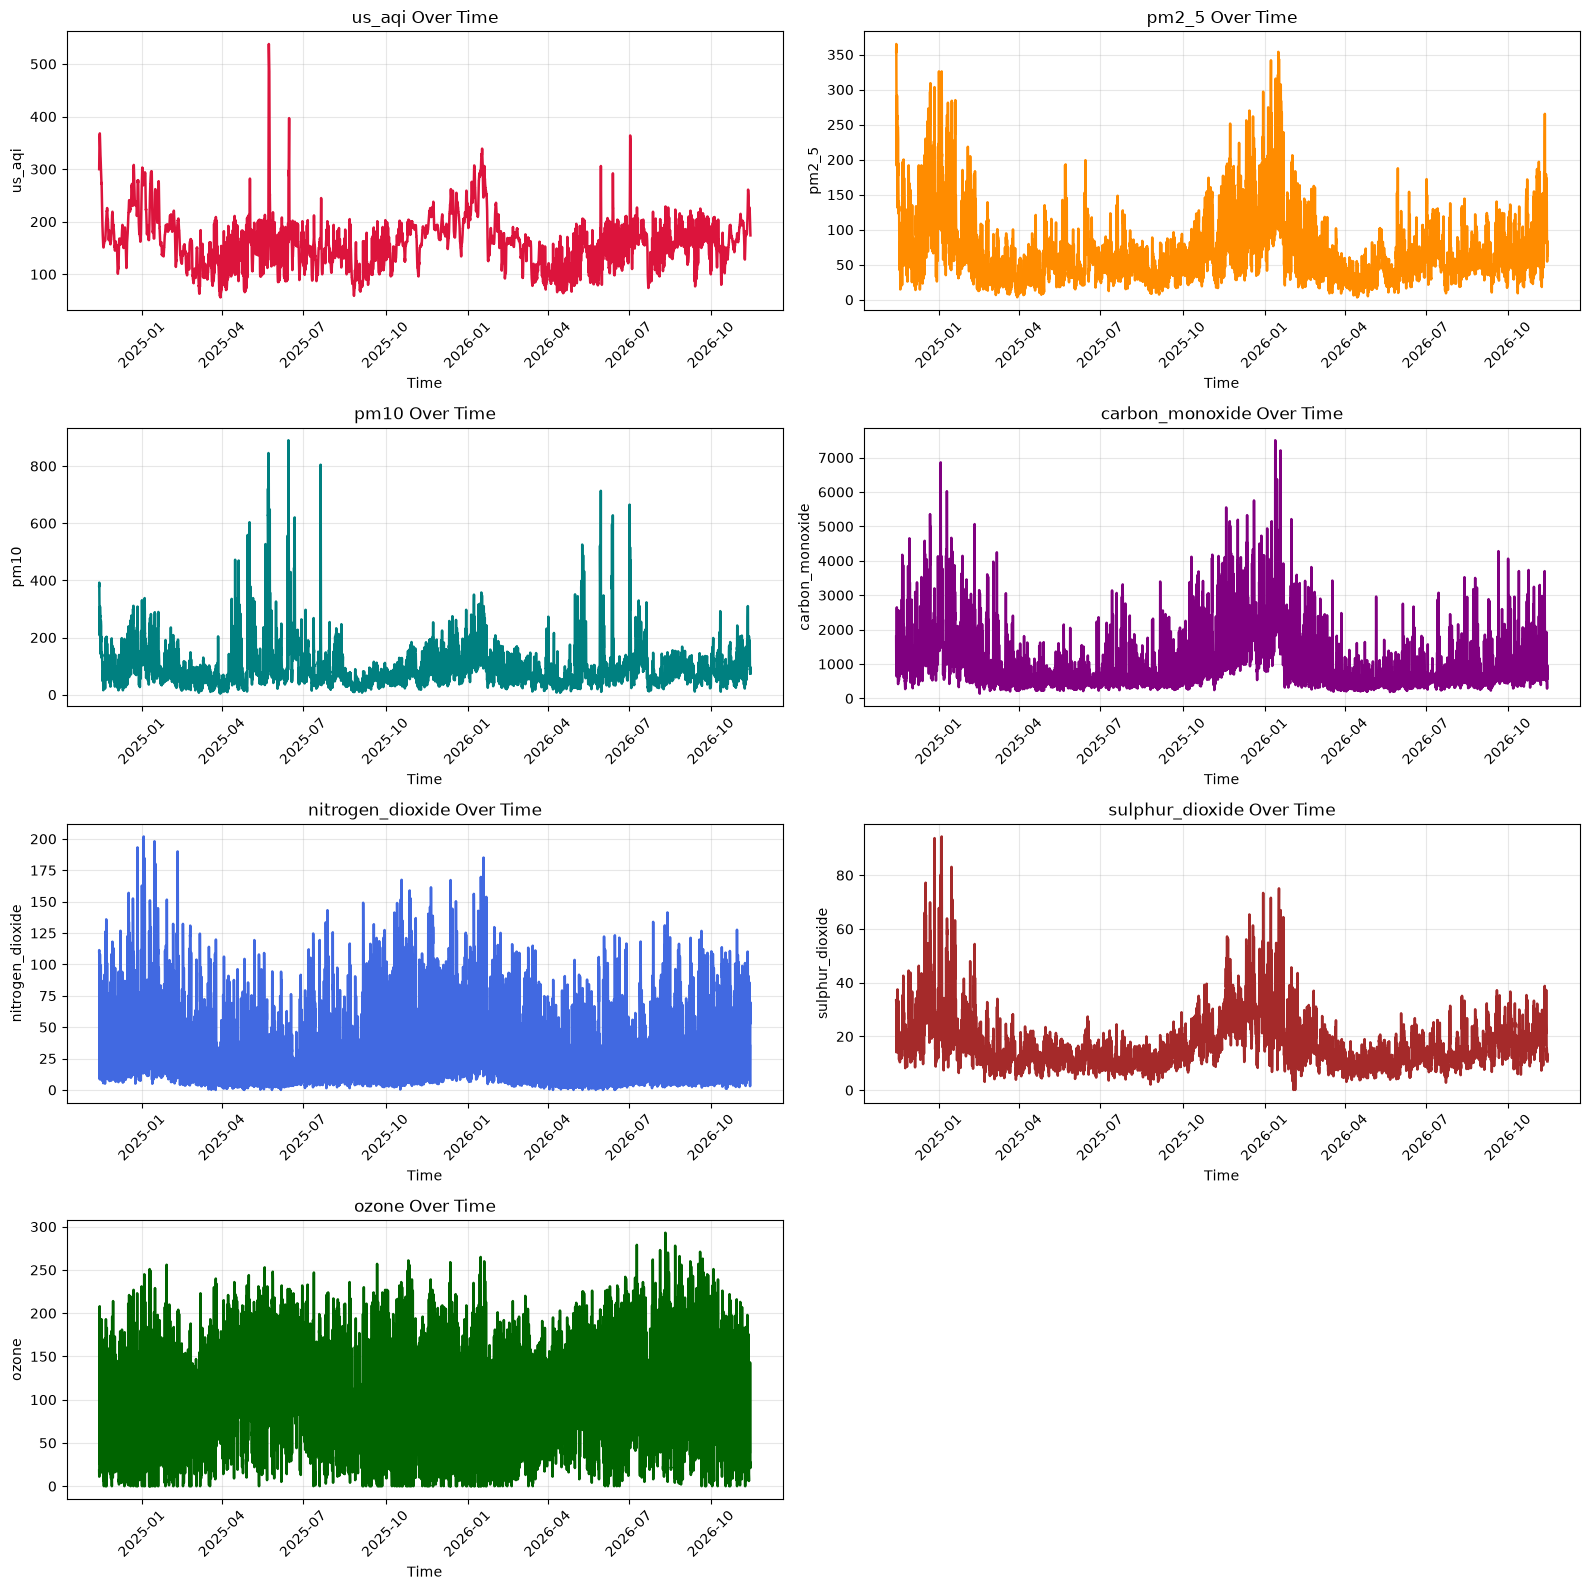

In [ ]:
air_quality_columns = [
    "us_aqi",
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

colors = [
    "crimson",
    "darkorange",
    "teal",
    "purple",
    "royalblue",
    "brown",
    "darkgreen"
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 16)
)

axes = axes.flatten()

for i, column in enumerate(air_quality_columns):
    axes[i].plot(
        historical_df["time"],
        historical_df[column],
        color=colors[i],
        linewidth=1.8
    )

    axes[i].set_title(f"{column} Over Time")
    axes[i].set_xlabel("Time")
    axes[i].set_ylabel(column)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(alpha=0.3)


axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

Preciptation, Precipitation probability and Wind Direction over time

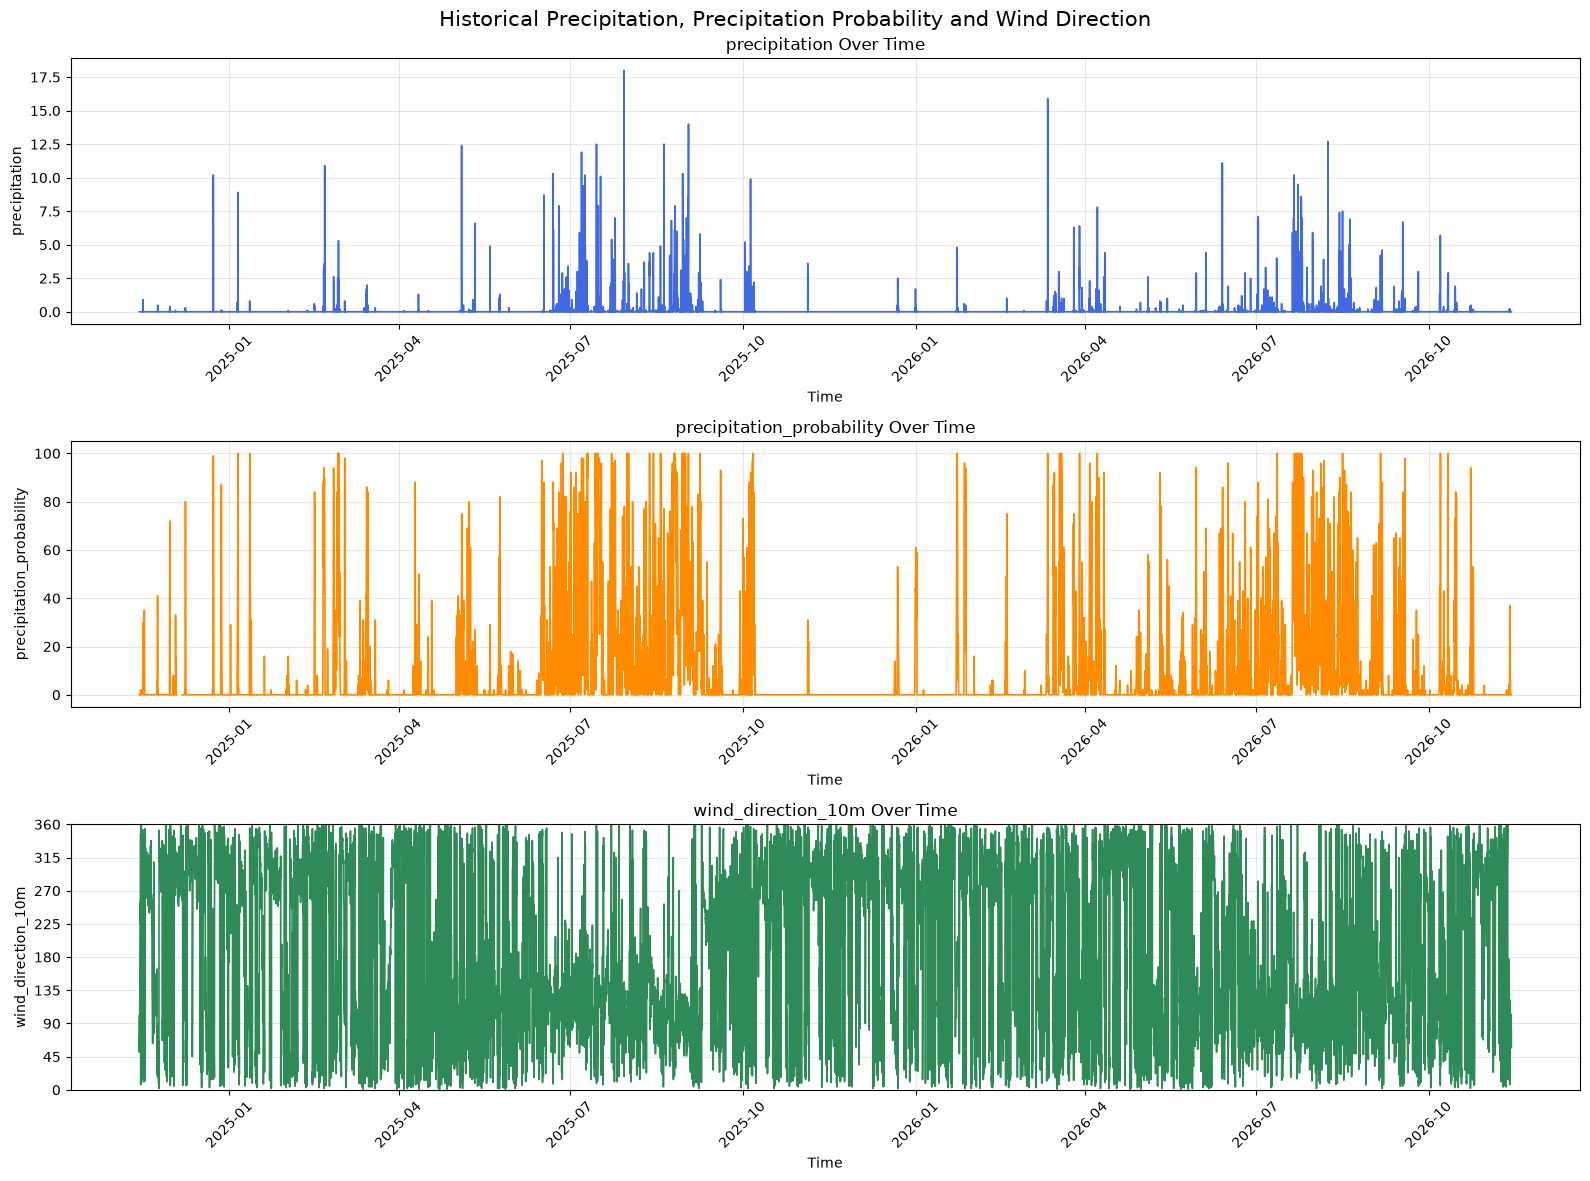

In [33]:
weather_columns = [
    "precipitation",
    "precipitation_probability",
    "wind_direction_10m"
]

colors = ["royalblue", "darkorange", "seagreen"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 12)
)

for i, column in enumerate(weather_columns):

    axes[i].plot(
        historical_df["time"],
        historical_df[column],
        color=colors[i],
        linewidth=1.2
    )

    axes[i].set_title(f"{column} Over Time")
    axes[i].set_xlabel("Time")
    axes[i].set_ylabel(column)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(alpha=0.3)

# Set wind direction axis limits
axes[2].set_ylim(0, 360)
axes[2].set_yticks(range(0, 361, 45))

plt.suptitle(
    "Historical Precipitation, Precipitation Probability and Wind Direction",
    fontsize=15
)

plt.tight_layout()
plt.show()

Correlation Analysis

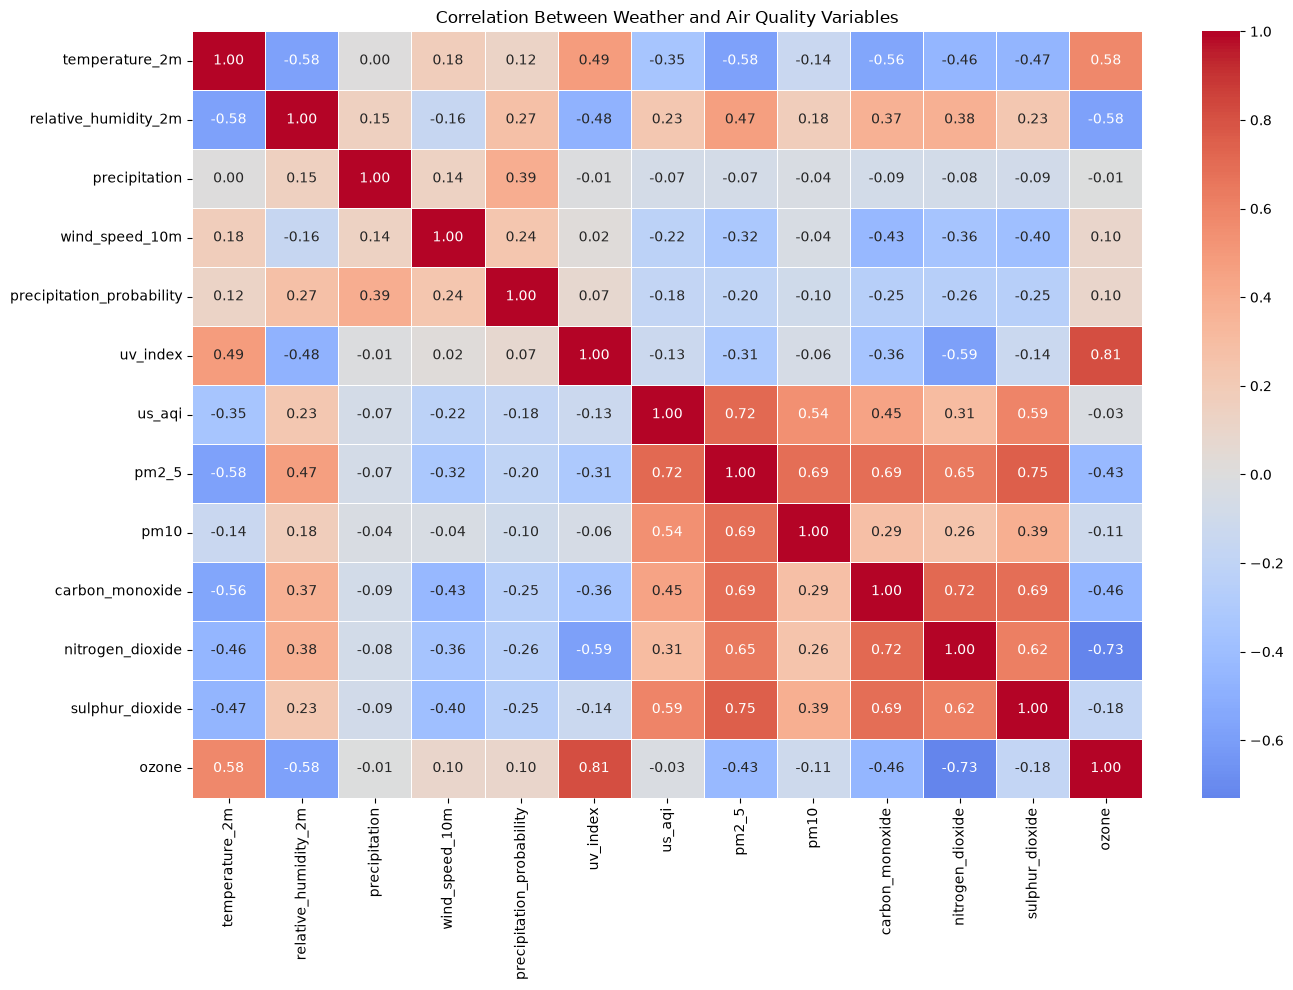

In [24]:
# Selecting numerical columns
correlation_columns = historical_df.select_dtypes(
    include=np.number
).columns.tolist()

# Excluding wind direction because it is a circular variable
correlation_columns.remove("wind_direction_10m")

# Removing constant columns 
correlation_columns = [
    col for col in correlation_columns
    if historical_df[col].nunique() > 1
]

# Calculating correlation matrix
correlation_matrix = historical_df[correlation_columns].corr()

# Plotting heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Between Weather and Air Quality Variables")
plt.tight_layout()
plt.show()

Hourly patterns

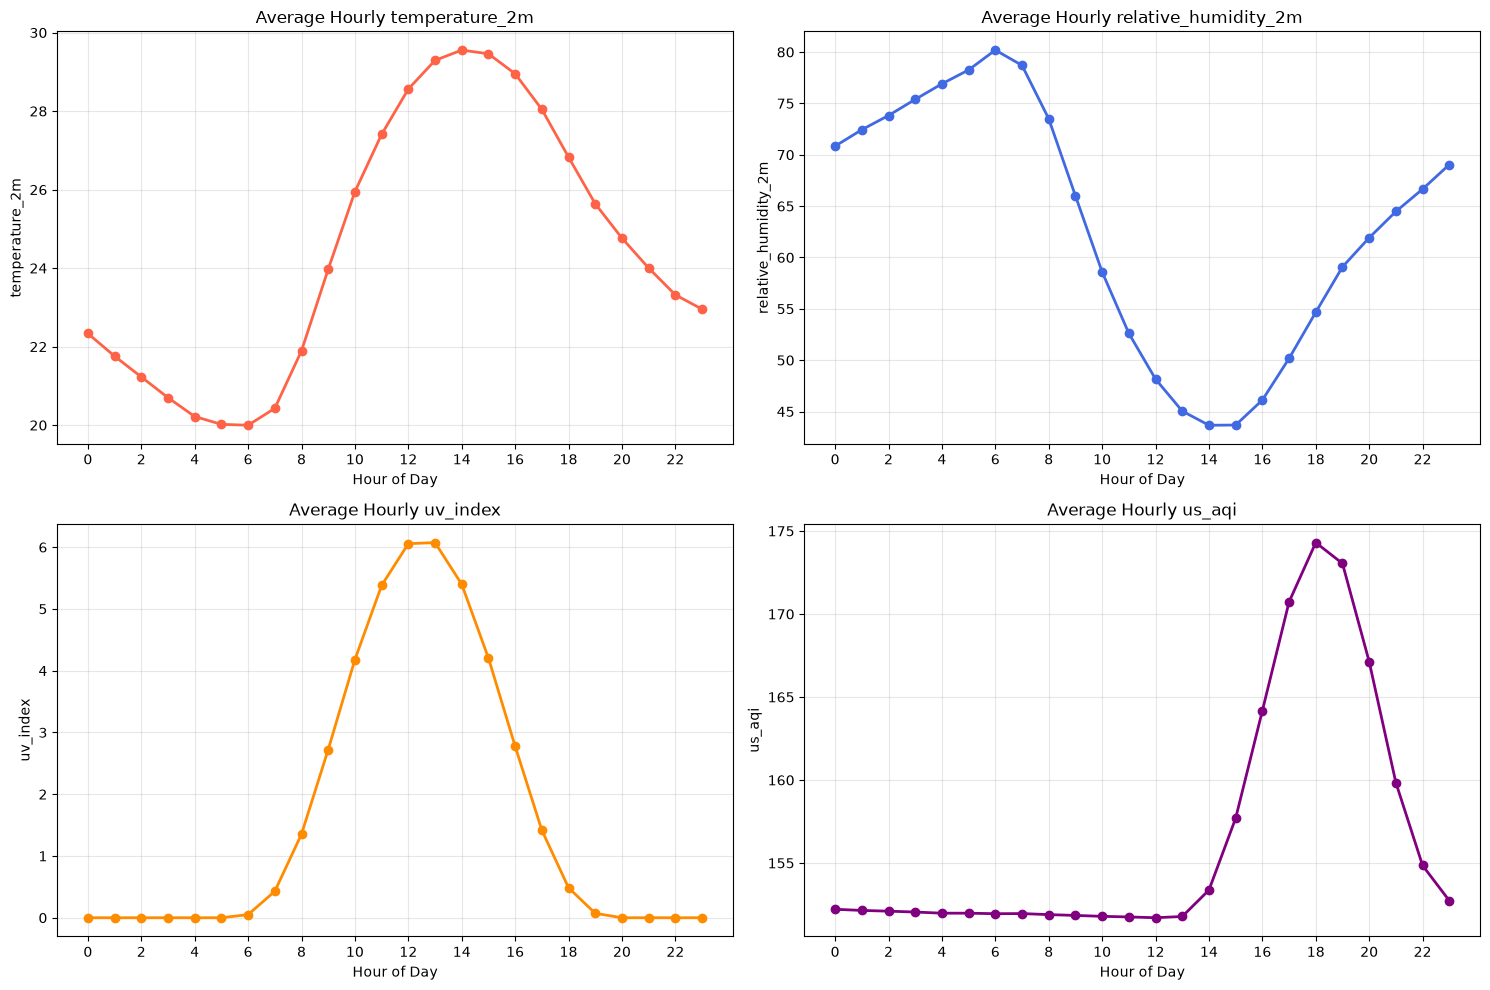

In [26]:
# Extracting hour from timestamp
historical_df["hour"] = historical_df["time"].dt.hour

# Selecting variables for hourly pattern analysis
hourly_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "uv_index",
    "us_aqi"
]

# Calculating hourly averages
hourly_patterns = historical_df.groupby("hour")[hourly_columns].mean()

# Plotting hourly patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

colors = ["tomato", "royalblue", "darkorange", "purple"]

for i, column in enumerate(hourly_columns):
    axes[i].plot(
        hourly_patterns.index,
        hourly_patterns[column],
        marker="o",
        color=colors[i],
        linewidth=2
    )

    axes[i].set_title(f"Average Hourly {column}")
    axes[i].set_xlabel("Hour of Day")
    axes[i].set_ylabel(column)
    axes[i].set_xticks(range(0, 24, 2))
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Daily trends

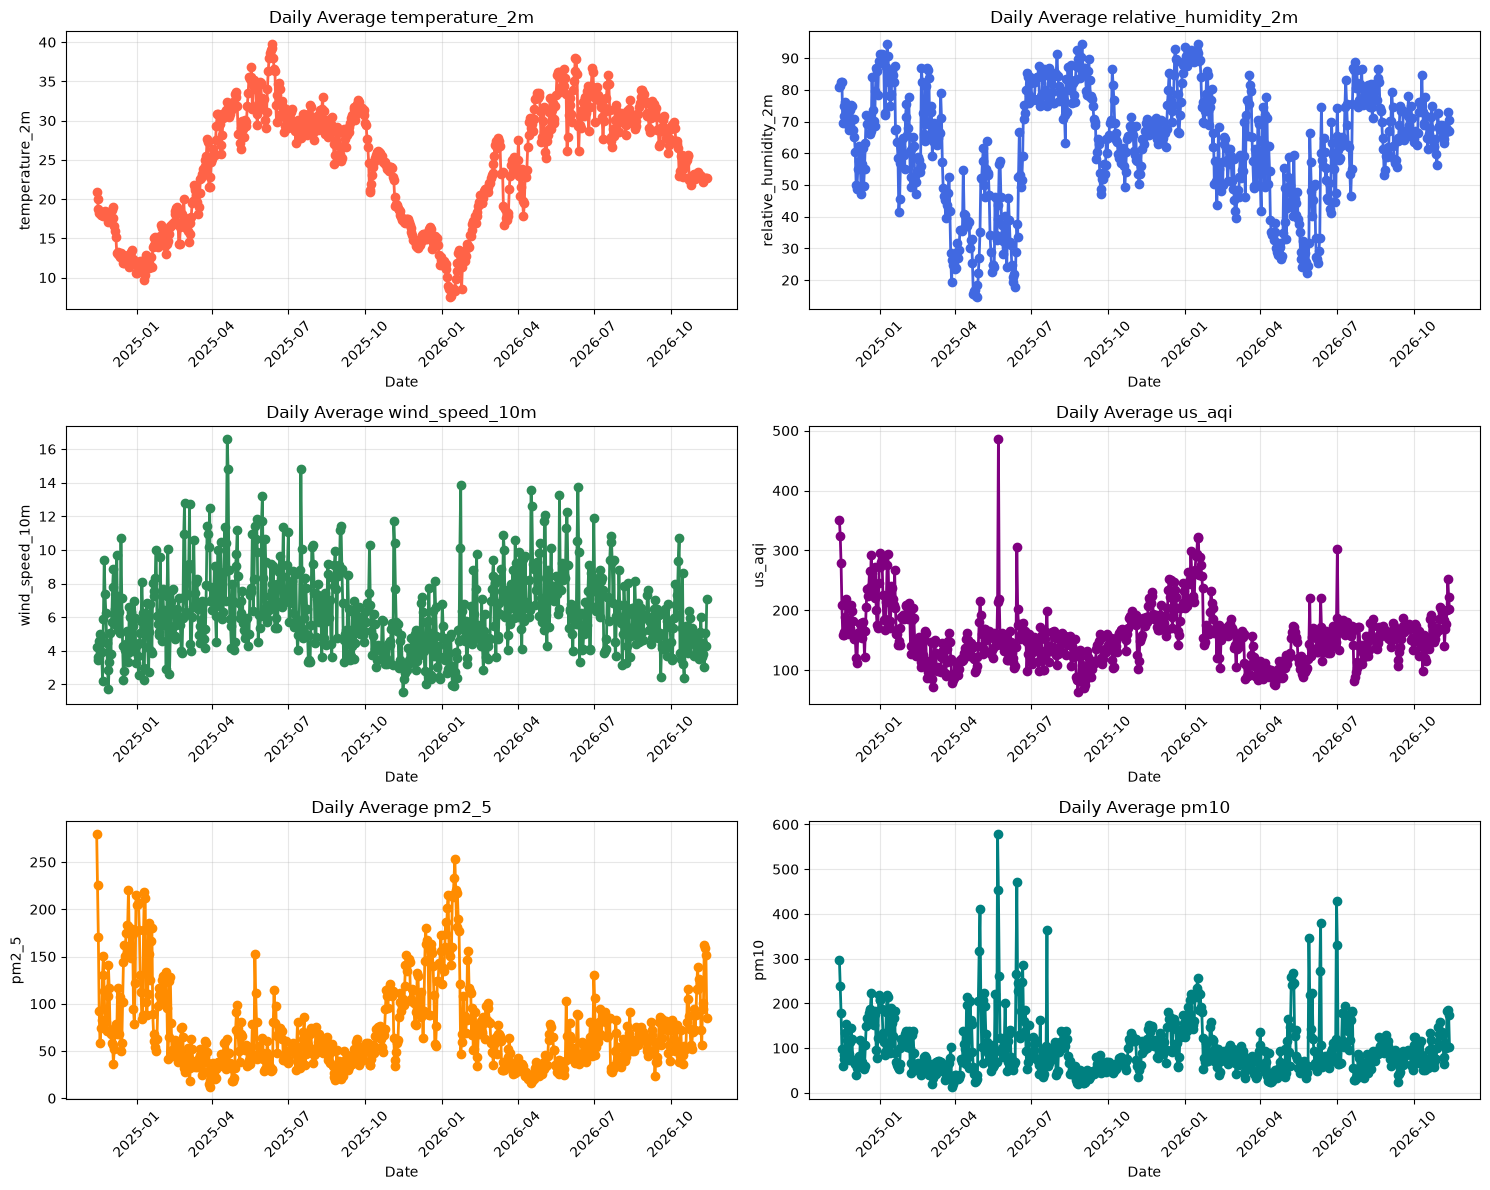

In [27]:
# Extracting date from timestamp
historical_df["date"] = historical_df["time"].dt.date

# Calculating daily averages
daily_patterns = historical_df.groupby("date").agg({
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "wind_speed_10m": "mean",
    "us_aqi": "mean",
    "pm2_5": "mean",
    "pm10": "mean"
})

# Plotting daily trends
daily_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "us_aqi",
    "pm2_5",
    "pm10"
]

colors = [
    "tomato", "royalblue", "seagreen",
    "purple", "darkorange", "teal"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(daily_columns):
    axes[i].plot(
        daily_patterns.index,
        daily_patterns[column],
        marker="o",
        color=colors[i],
        linewidth=2
    )

    axes[i].set_title(f"Daily Average {column}")
    axes[i].set_xlabel("Date")
    axes[i].set_ylabel(column)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Seasonal patterns across the two years

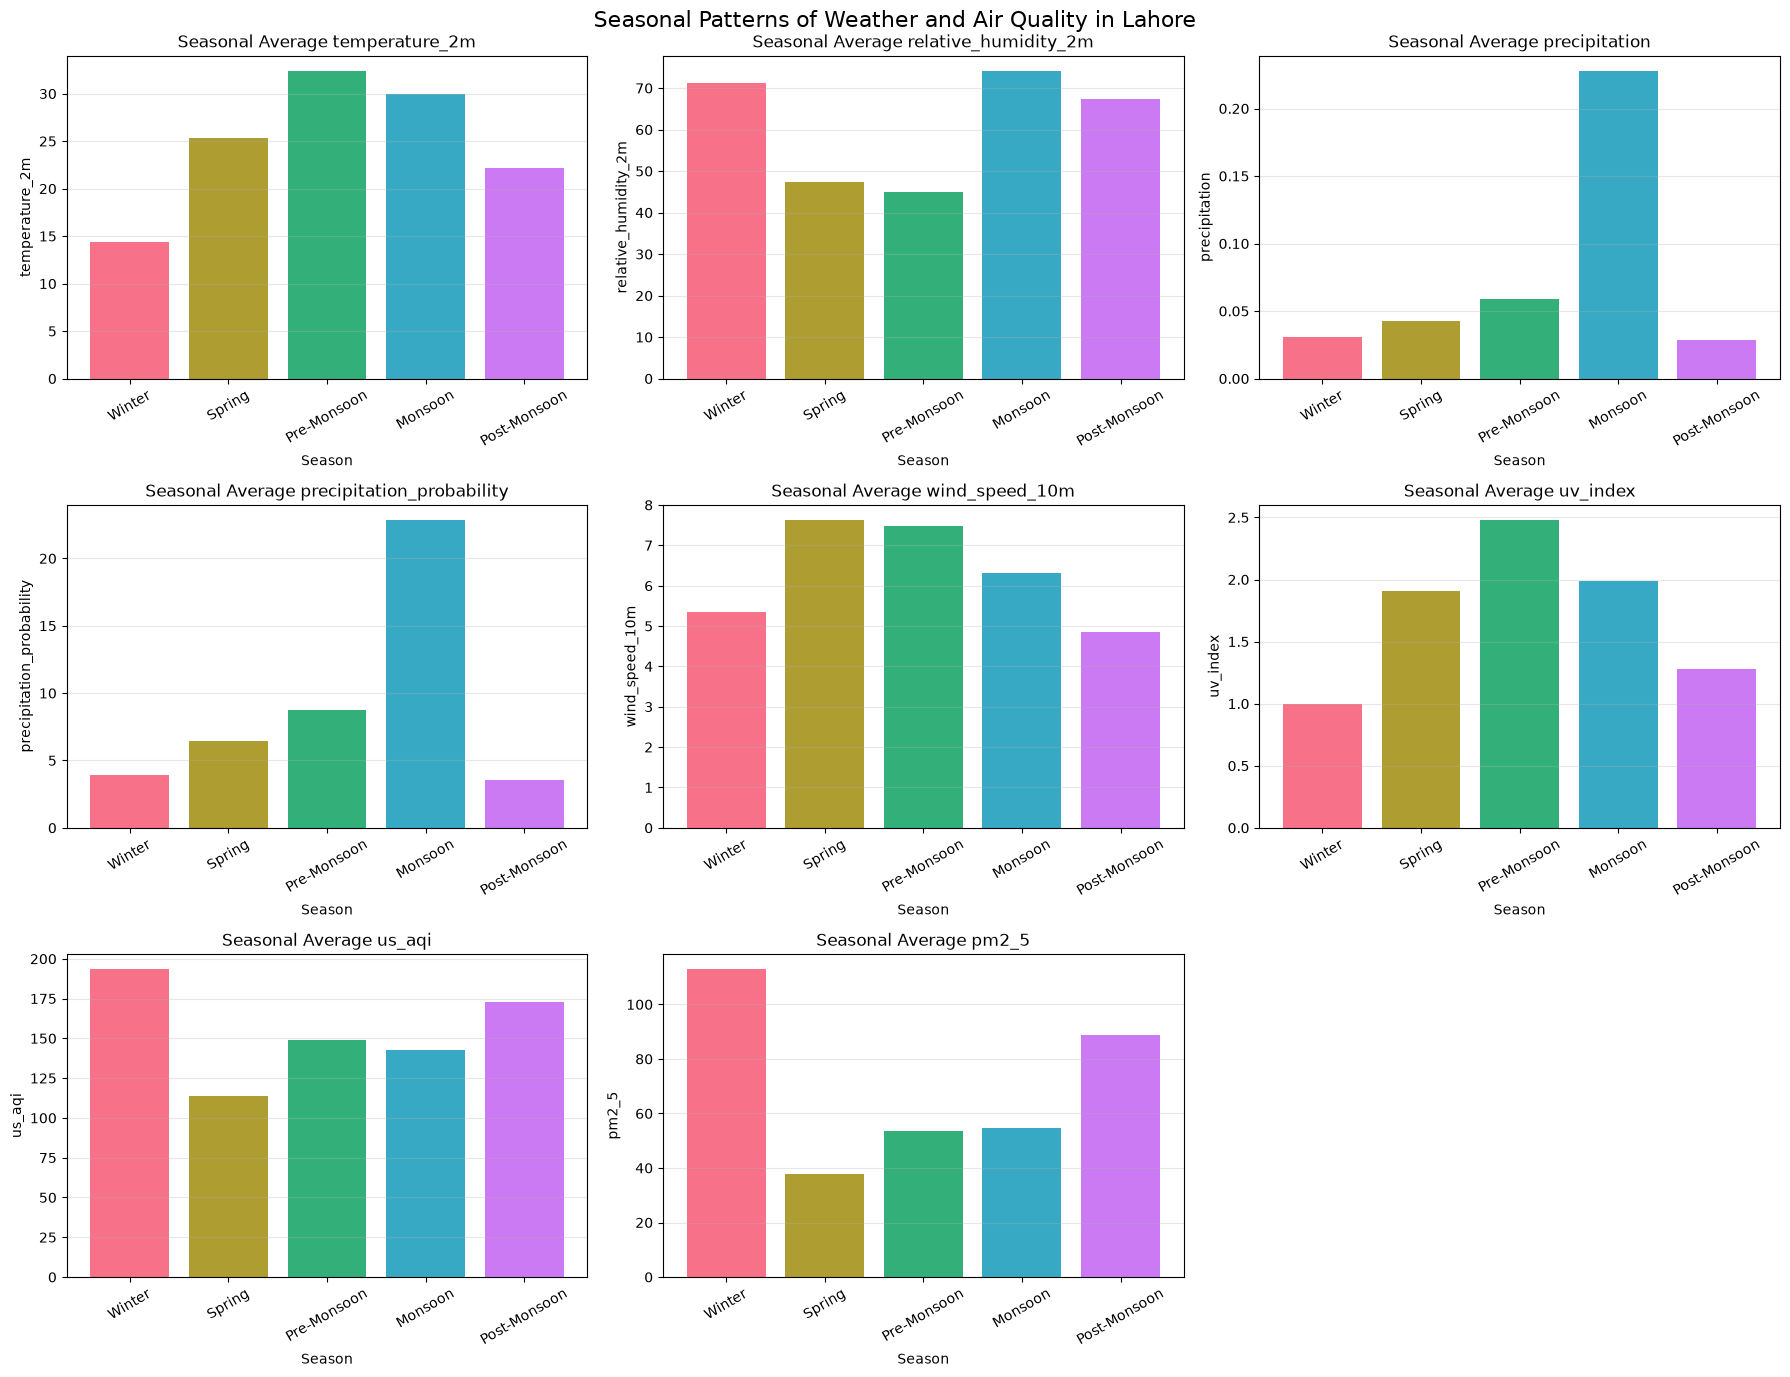

In [34]:
# Defining seasons based on Lahore's climate
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Pre-Monsoon",
    6: "Pre-Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-Monsoon",
    11: "Post-Monsoon"
}

# Assigning seasons to each observation
historical_df["season"] = (
    historical_df["time"].dt.month.map(season_mapping)
)

# Selecting variables for seasonal analysis
seasonal_columns = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "precipitation_probability",
    "wind_speed_10m",
    "uv_index",
    "us_aqi",
    "pm2_5"
]

# Defining the correct seasonal order
season_order = [
    "Winter",
    "Spring",
    "Pre-Monsoon",
    "Monsoon",
    "Post-Monsoon"
]

# Calculating seasonal averages
seasonal_patterns = (
    historical_df.groupby("season")[seasonal_columns]
    .mean()
    .reindex(season_order)
)

# Plotting seasonal patterns
fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(18, 14)
)

axes = axes.flatten()

season_colors = sns.color_palette("husl", 5)

for i, column in enumerate(seasonal_columns):

    axes[i].bar(
        seasonal_patterns.index,
        seasonal_patterns[column],
        color=season_colors
    )

    axes[i].set_title(f"Seasonal Average {column}")
    axes[i].set_xlabel("Season")
    axes[i].set_ylabel(column)
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].grid(axis="y", alpha=0.3)

# Hiding unused subplot
axes[-1].set_visible(False)

plt.suptitle(
    "Seasonal Patterns of Weather and Air Quality in Lahore",
    fontsize=16
)

plt.tight_layout()
plt.show()

Seasonal trends

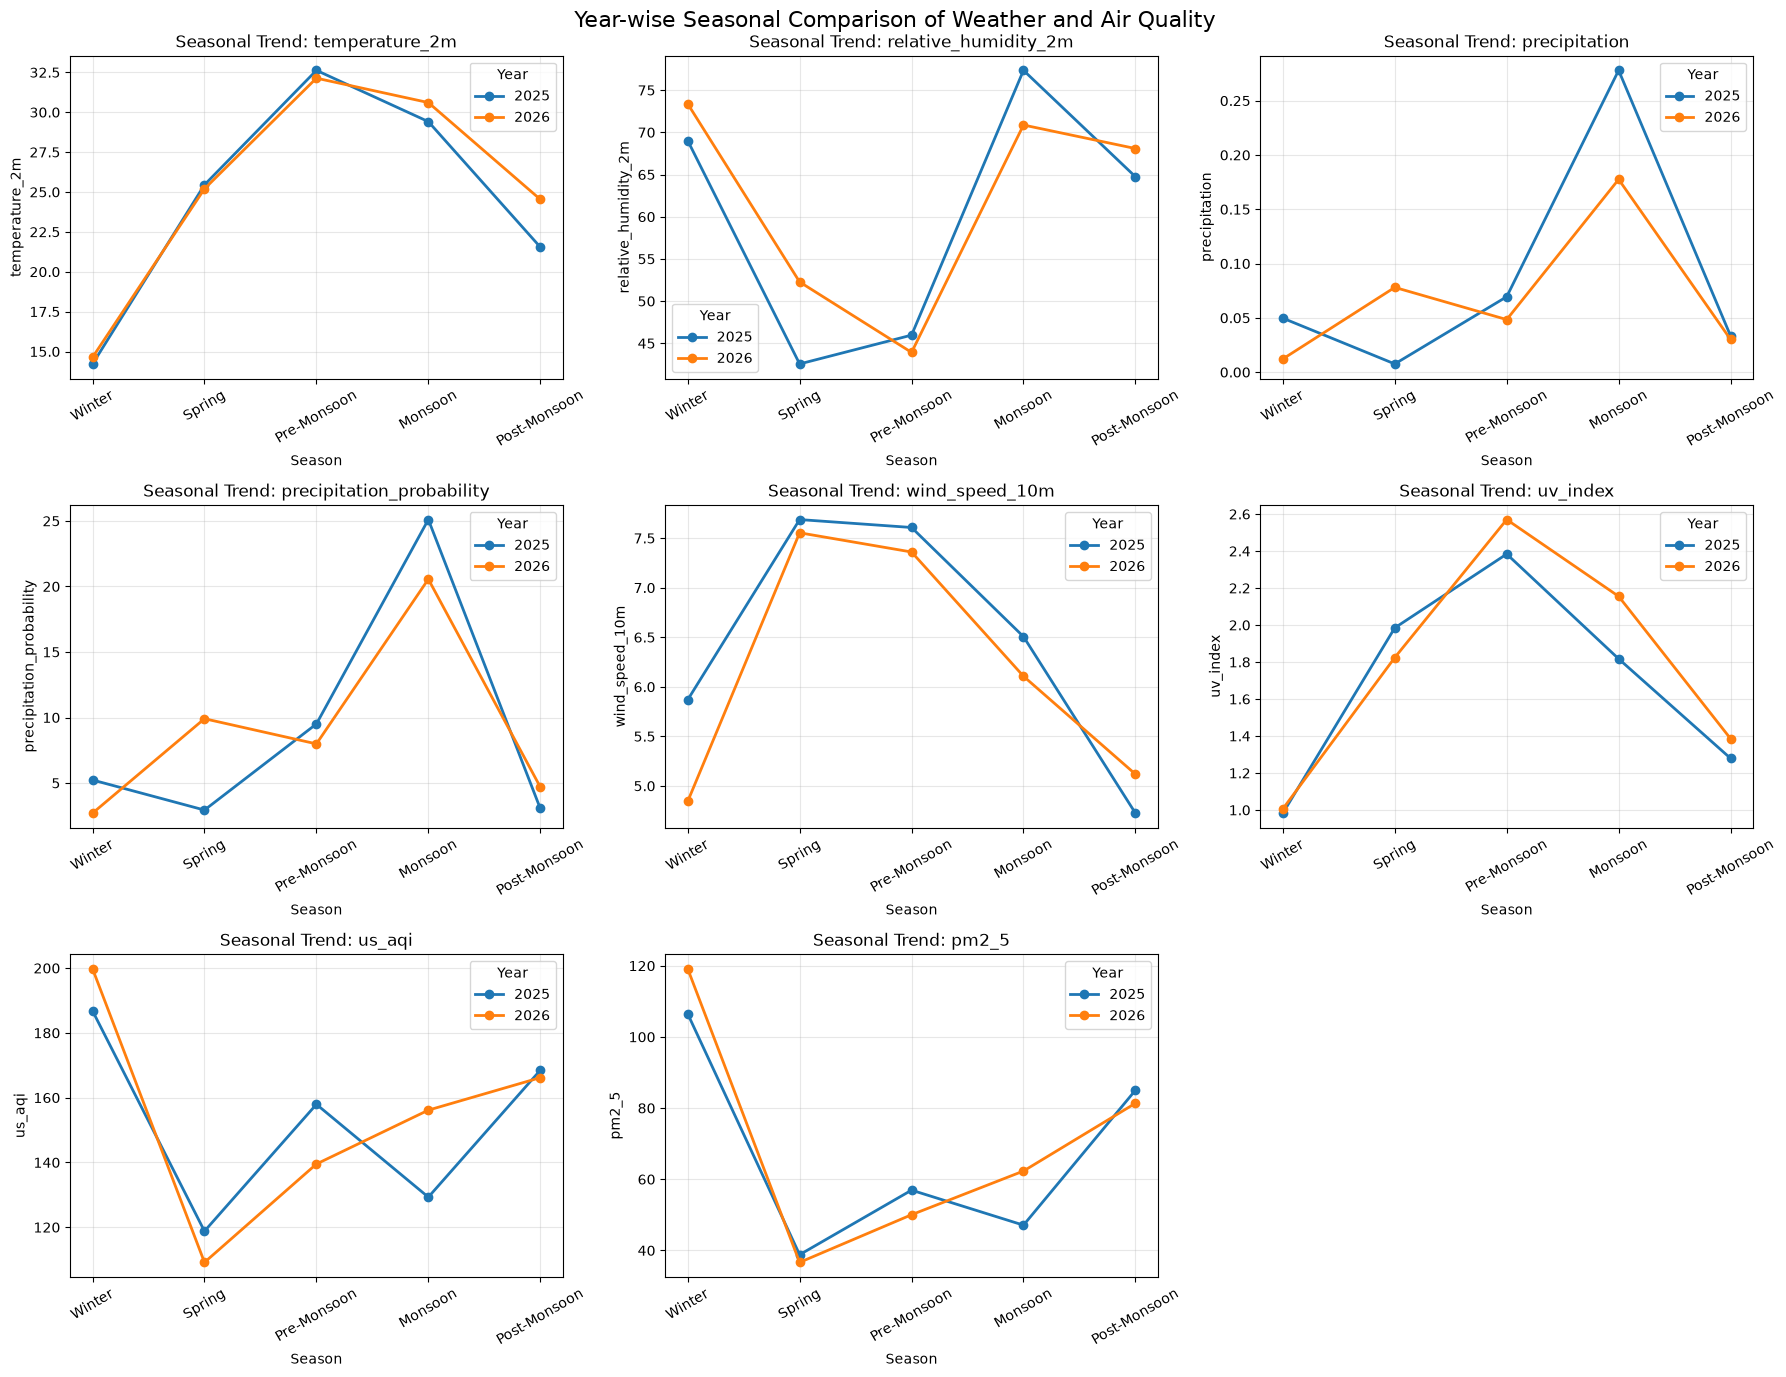

In [35]:
# Assigning a season-year
# December belongs to the following winter year
historical_df["season_year"] = (
    historical_df["time"].dt.year
    + (historical_df["time"].dt.month == 12).astype(int)
)

# Calculating averages for each season in each year
yearly_seasonal_patterns = (
    historical_df.groupby(["season_year", "season"])[seasonal_columns]
    .mean()
    .reset_index()
)

# Excluding 2024 because our historical data starts in November
yearly_seasonal_patterns = yearly_seasonal_patterns[
    yearly_seasonal_patterns["season_year"] >= 2025
]

# Plotting year-wise seasonal comparisons
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, column in enumerate(seasonal_columns):

    for year in sorted(yearly_seasonal_patterns["season_year"].unique()):

        year_data = yearly_seasonal_patterns[
            yearly_seasonal_patterns["season_year"] == year
        ].set_index("season").reindex(season_order)

        axes[i].plot(
            season_order,
            year_data[column],
            marker="o",
            linewidth=2,
            label=str(year)
        )

    axes[i].set_title(f"Seasonal Trend: {column}")
    axes[i].set_xlabel("Season")
    axes[i].set_ylabel(column)
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].legend(title="Year")
    axes[i].grid(alpha=0.3)

axes[-1].set_visible(False)

plt.suptitle(
    "Year-wise Seasonal Comparison of Weather and Air Quality",
    fontsize=16
)

plt.tight_layout()
plt.show()

Outlier Analysis

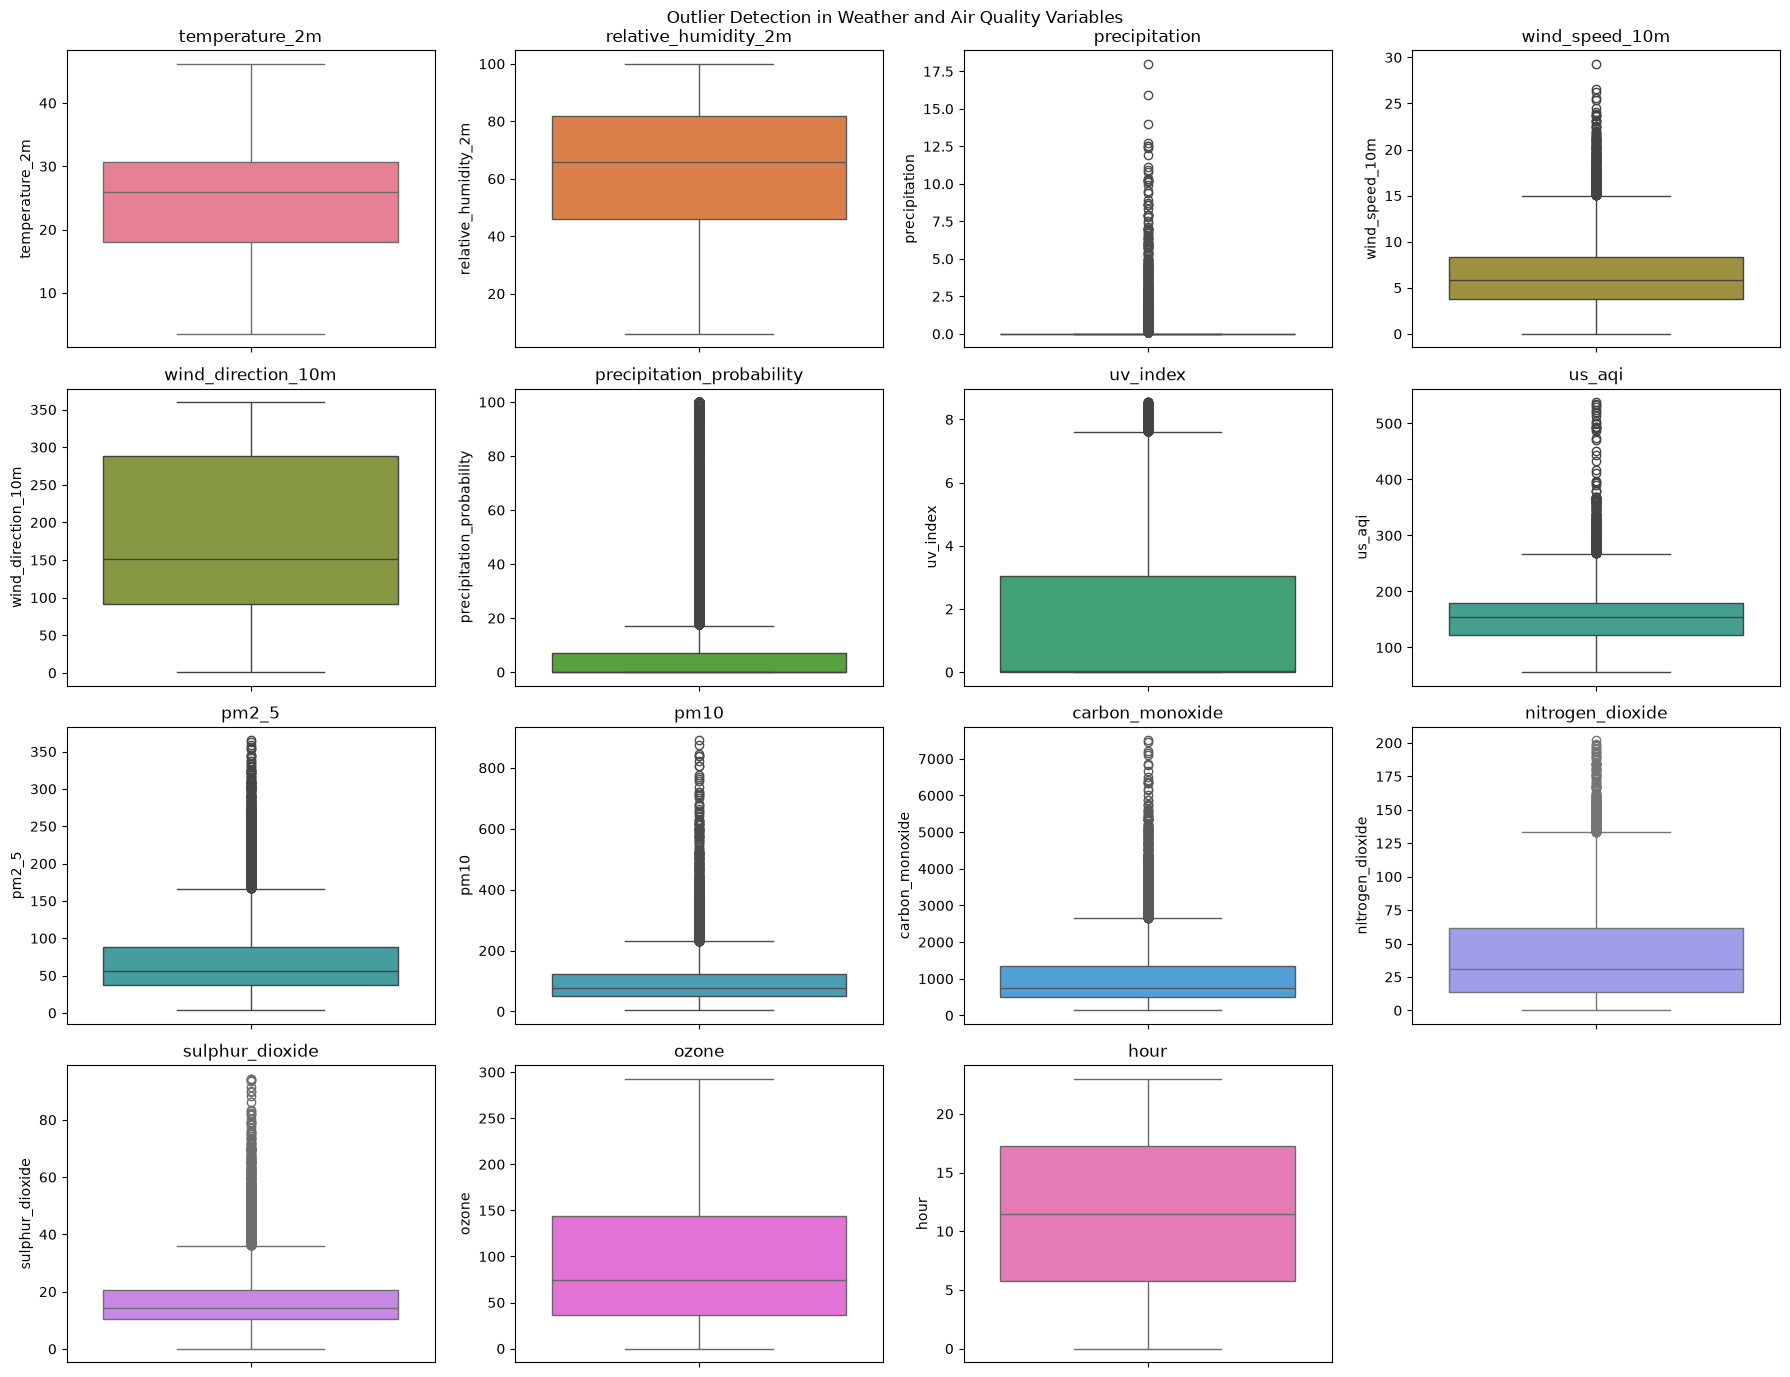

In [28]:
# Selecting numerical variables
numeric_columns = historical_df.select_dtypes(
    include=np.number
).columns.tolist()

# Excluding constant columns
numeric_columns = [
    col for col in numeric_columns
    if historical_df[col].nunique() > 1
]

# Creating boxplots
fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(18, 14)
)

axes = axes.flatten()

for i, column in enumerate(numeric_columns):
    sns.boxplot(
        y=historical_df[column],
        color=sns.color_palette("husl", len(numeric_columns))[i],
        ax=axes[i]
    )

    axes[i].set_title(column)


for i in range(len(numeric_columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle("Outlier Detection in Weather and Air Quality Variables")
plt.tight_layout()
plt.show()

Statistical summary of our dataset

In [29]:
# Selecting numerical columns
numeric_columns = historical_df.select_dtypes(
    include=np.number
).columns

# Calculating distribution statistics
distribution_stats = historical_df[numeric_columns].agg(
    ["mean", "median", "std", "min", "max", "skew"]
).T

# Adding kurtosis
distribution_stats["kurtosis"] = historical_df[numeric_columns].kurtosis()

distribution_stats

,mean,median,std,min,max,skew,kurtosis
temperature_2m,24.470257,25.90,8.306550,3.5,46.20,-0.250343,-0.724784
relative_humidity_2m,62.913756,66.00,22.686706,6.0,100.00,-0.381457,-0.798548
precipitation,0.086787,0.00,0.633169,0.0,18.00,12.570877,202.715943
wind_speed_10m,6.245188,5.80,3.471135,0.0,29.30,0.890735,1.477535
wind_direction_10m,181.149772,152.00,106.693936,1.0,360.00,0.119934,-1.423762
precipitation_probability,9.883796,0.00,21.289403,0.0,100.00,2.569993,6.034971
uv_index,1.691664,0.05,2.431988,0.0,8.55,1.287115,0.381476
us_aqi,156.458276,155.00,49.442107,56.0,538.00,1.138207,3.863257
pm2_5,71.658271,56.10,51.099267,3.4,365.10,1.739030,3.582317
pm10,98.405925,78.20,75.854987,3.6,890.30,2.972323,15.352313


Checking relationships between pollutants and AQI

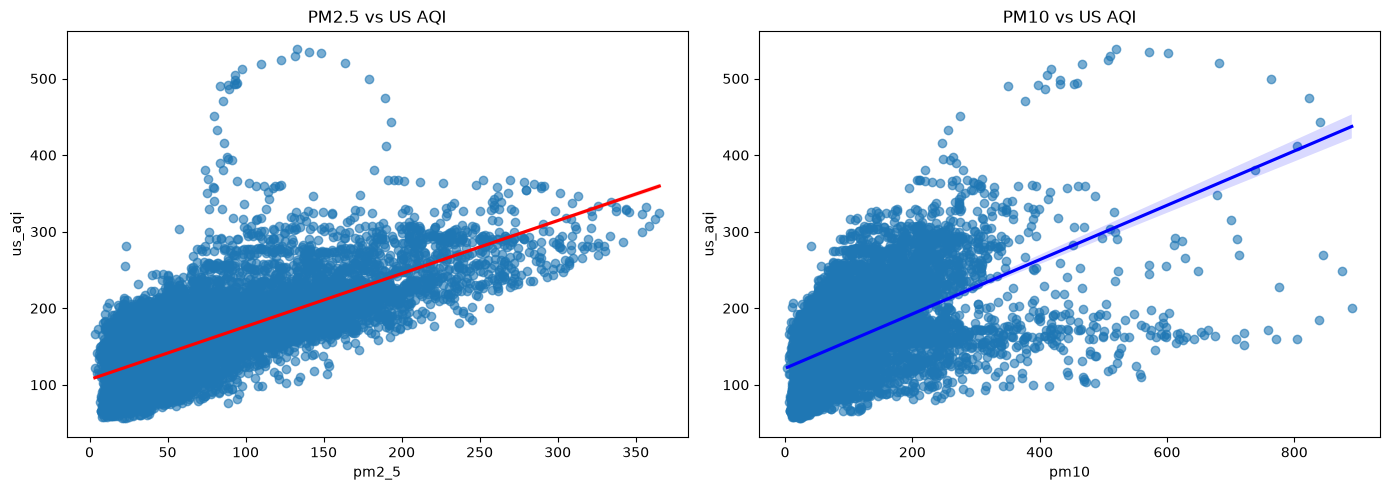

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=historical_df,
    x="pm2_5",
    y="us_aqi",
    ax=axes[0],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

axes[0].set_title("PM2.5 vs US AQI")

sns.regplot(
    data=historical_df,
    x="pm10",
    y="us_aqi",
    ax=axes[1],
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "blue"}
)

axes[1].set_title("PM10 vs US AQI")

plt.tight_layout()
plt.show()

Relationship between weather conditions and air quality

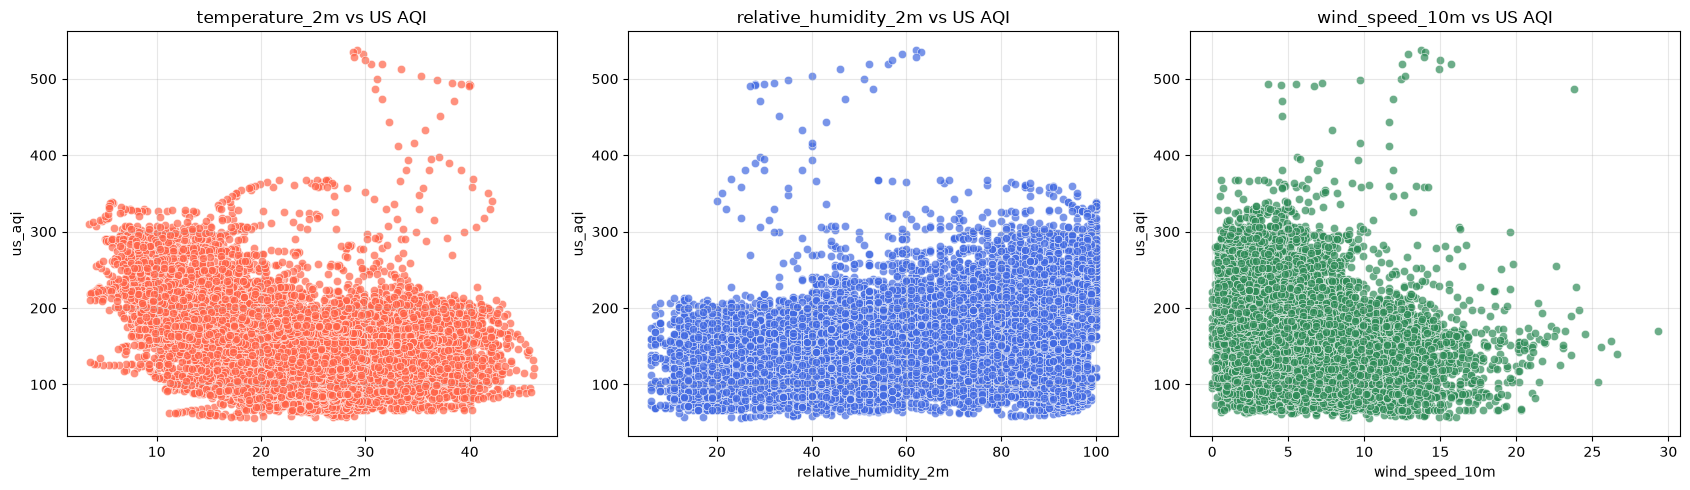

In [31]:
weather_variables = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

colors = ["tomato", "royalblue", "seagreen"]

for i, column in enumerate(weather_variables):
    sns.scatterplot(
        data=historical_df,
        x=column,
        y="us_aqi",
        color=colors[i],
        alpha=0.7,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} vs US AQI")
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()